# Solving the n-Queens Problem using Local Search

Student Name: Ngô Đông Ất (MSSV 3123410014, lớp DNT1241)

I have used the following AI tools: Claude (Anthropic) – hỗ trợ viết mã và soạn thảo; toàn bộ mã đã được chạy lại và kiểm tra bằng các phép kiểm thử trong notebook

I understand that my submission needs to be my own work: [your initials]

**Học phần:** Trí tuệ nhân tạo nâng cao – Lab 4: Bài toán thỏa mãn ràng buộc (CSP), phần n quân hậu (Bài 5–8)

## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file.

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## Môi trường chạy và thư viện

In [2]:
import os, sys, time, math, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import colors
from IPython.display import display, Markdown

FIG_DIR, RES_DIR = 'figures', 'results'      # đường dẫn tương đối: chạy lại được trên máy khác
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 200, 'savefig.bbox': 'tight'})

def save_fig(name):
    path = os.path.join(FIG_DIR, name)
    plt.savefig(path)
    print('Đã lưu hình:', path)

def save_table(df, name):
    path = os.path.join(RES_DIR, name)
    df.to_csv(path, index=False, encoding='utf-8-sig')
    print('Đã lưu bảng:', path)

print('Python', platform.python_version(), '|', platform.system())
print('numpy', np.__version__, '| matplotlib', matplotlib.__version__, '| pandas', pd.__version__)

Python 3.12.3 | Linux
numpy 2.4.4 | matplotlib 3.10.8 | pandas 3.0.2


## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum.

## Helper functions

In [3]:
np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""

    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)

    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n

    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1

    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

def draw_board(board, ax, cols = ['white', 'gray'], fontsize = None, title = None):
    """Vẽ bàn cờ lên một trục ax (tách khỏi show_board để vẽ nhiều bàn cờ trong một hình)."""
    n = len(board)
    if fontsize is None:
        fontsize = max(12, int(200 / n))           # tự điều chỉnh cỡ chữ theo kích thước bàn cờ

    # create chess board display
    display_arr = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0):
                display_arr[i,j] = 1

    cmap = colors.ListedColormap(cols)
    ax.imshow(display_arr, cmap = cmap,
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])

    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        ax.text(j, board[j], u"\u265B", fontsize = fontsize,
                horizontalalignment = 'center',
                verticalalignment = 'center')
    if title:
        ax.set_title(title)

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = None, save = None):
    """display the board (save: tên file ảnh để lưu vào thư mục figures/)"""

    n = len(board)
    fig, ax = plt.subplots()
    draw_board(board, ax, cols, fontsize, title = f'n = {n}, h(board) = {conflicts(board)}')

    print(f"Board with {conflicts(board)} conflicts.")
    if save:
        save_fig(save)
    plt.show()

## Create a board

Board with 4 conflicts.
Đã lưu hình: figures/nq_01_ban_co_ngau_nhien_n4.png


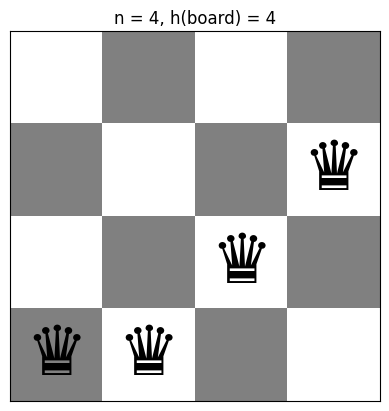

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [4]:
board = random_board(4)

show_board(board, save='nq_01_ban_co_ngau_nhien_n4.png')
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


Đã lưu hình: figures/nq_02_ban_co_mau_khong_xung_dot_n4.png


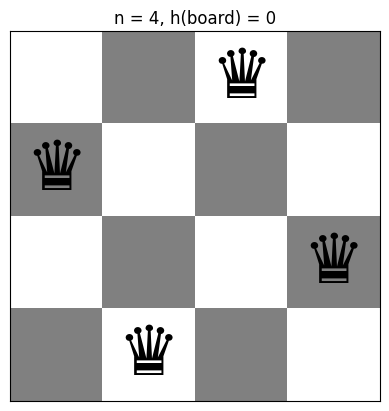

In [5]:
board = [1,3,0,2]
show_board(board, save='nq_02_ban_co_mau_khong_xung_dot_n4.png')

# Bài 5. Biểu diễn bài toán n quân hậu

Mỗi cột có đúng một quân hậu, `board[i]` là chỉ số **hàng** của quân hậu ở cột $i$. Hàm mục tiêu (cần cực tiểu hóa) là **số cặp quân hậu cùng hàng hoặc cùng đường chéo**:

$$h(\mathbf{q}) = \sum_{i<j} \Big[\, q_i = q_j \;\lor\; |q_i - q_j| = |i - j| \,\Big]$$

Hai quân ở khác cột nên không bao giờ cùng cột. Hàm `conflicts` cài đặt $h$ một cách nhanh bằng cách đếm số quân trên mỗi hàng và mỗi đường chéo rồi cộng $\binom{m}{2}$ cho mỗi nhóm có $m$ quân. Ta kiểm chứng điều đó bằng cách đếm trực tiếp các cặp tấn công, và kiểm tra $h = 0$ khi và chỉ khi không có cặp nào tấn công nhau.

In [6]:
def attacking_pairs(board):
    """Đếm trực tiếp các cặp quân hậu tấn công nhau (cùng hàng hoặc cùng đường chéo) - O(n^2)."""
    n = len(board)
    return sum(1 for i in range(n) for j in range(i + 1, n)
               if board[i] == board[j] or abs(board[i] - board[j]) == j - i)

np.random.seed(5)
for n_ in [4, 8]:
    boards = [random_board(n_) for _ in range(2000)]
    same = all(conflicts(b) == attacking_pairs(b) for b in boards)
    iff = all((conflicts(b) == 0) == (attacking_pairs(b) == 0) for b in boards)
    print(f'n = {n_}: conflicts() == số cặp tấn công trên 2000 bàn cờ ngẫu nhiên: {same} | h = 0 <=> không có cặp tấn công: {iff}')
    assert same and iff

# n = 4: duyệt toàn bộ 4^4 = 256 bàn cờ (mỗi cột một quân)
import itertools
sols4 = [list(b) for b in itertools.product(range(4), repeat=4) if conflicts(b) == 0]
print('Số nghiệm của 4-Queens (mỗi cột một quân):', len(sols4), '->', sols4)

n = 4: conflicts() == số cặp tấn công trên 2000 bàn cờ ngẫu nhiên: True | h = 0 <=> không có cặp tấn công: True


n = 8: conflicts() == số cặp tấn công trên 2000 bàn cờ ngẫu nhiên: True | h = 0 <=> không có cặp tấn công: True
Số nghiệm của 4-Queens (mỗi cột một quân): 2 -> [[1, 3, 0, 2], [2, 0, 3, 1]]


Đã lưu hình: figures/nq_03_ban_co_n4_n8_va_h.png


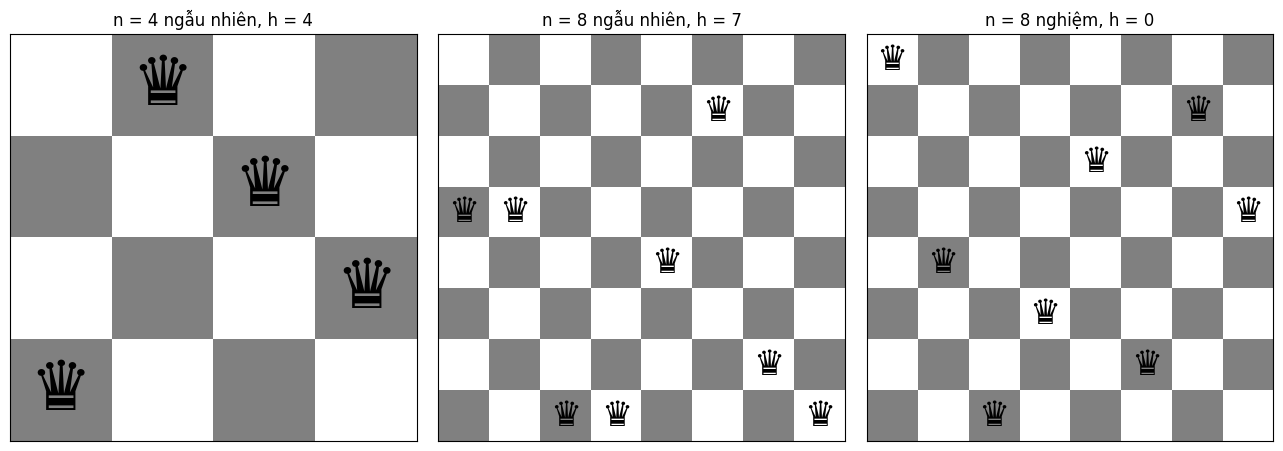

board4 = [3, 0, 1, 2] | board8 = [3, 3, 7, 7, 4, 1, 6, 7]


In [7]:
np.random.seed(7)
board4 = random_board(4)
board8 = random_board(8)
solution8 = [0, 4, 7, 5, 2, 6, 1, 3]             # một nghiệm quen thuộc của 8 quân hậu
assert conflicts(solution8) == 0

fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
draw_board(board4, axes[0], title=f'n = 4 ngẫu nhiên, h = {conflicts(board4)}')
draw_board(board8, axes[1], title=f'n = 8 ngẫu nhiên, h = {conflicts(board8)}')
draw_board(solution8, axes[2], title=f'n = 8 nghiệm, h = {conflicts(solution8)}')
plt.tight_layout()
save_fig('nq_03_ban_co_n4_n8_va_h.png')
plt.show()
print('board4 =', list(map(int, board4)), '| board8 =', list(map(int, board8)))

**Nhận xét Bài 5.** Hàm `conflicts` trùng khớp với phép đếm trực tiếp các cặp tấn công trên 2 000 bàn cờ ngẫu nhiên cho mỗi cỡ $n = 4, 8$, và $h = 0$ đúng khi không có cặp quân hậu nào tấn công nhau. Với $n=4$, trong $4^4 = 256$ bàn cờ (mỗi cột một quân) chỉ có **2 nghiệm**: `[1, 3, 0, 2]` và `[2, 0, 3, 1]` (đối xứng gương của nhau). Giá trị $h$ của từng bàn cờ minh họa được in trong tiêu đề của hình.

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision.
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally.
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

**Quy ước chung của các thí nghiệm:** mọi thuật toán dùng cùng hàm mục tiêu `conflicts` và cùng không gian trạng thái; số lần đánh giá hàm mục tiêu (`evals`) được đếm trực tiếp trong từng thuật toán; thời gian đo bằng `time.perf_counter()`; mỗi thí nghiệm đặt `np.random.seed(...)` trước khi sinh dữ liệu để lặp lại được.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum.

**Cài đặt.** Mỗi bước đánh giá toàn bộ $n(n-1)$ láng giềng (đổi hàng của một quân trong cột của nó), chọn nước đi có $h$ nhỏ nhất; nếu nhiều nước bằng nhau thì chọn ngẫu nhiên giữa chúng. **Chỉ chấp nhận nước đi cải thiện thực sự** ($h$ giảm); nếu không có nước nào cải thiện thì dừng – đó là cực tiểu cục bộ hoặc plateau (vùng phẳng). Hàm trả về bàn cờ cuối, $h$ cuối, số bước, số lần đánh giá $h$ và vết hội tụ.

In [8]:
def neighbor_values(board):
    """Đánh giá h cho TẤT CẢ n(n-1) láng giềng (đổi hàng của một quân trong cột của nó)."""
    n = len(board)
    out = []
    for c in range(n):
        old = board[c]
        for r in range(n):
            if r == old:
                continue
            board[c] = r
            out.append((c, r, conflicts(board)))
        board[c] = old
    return out

def steepest_ascent(board):
    board = np.array(board)
    h = conflicts(board)
    evals, steps = 1, 0
    trace_h, trace_evals = [h], [evals]
    while h > 0:
        vals = neighbor_values(board)
        evals += len(vals)
        best_h = min(v[2] for v in vals)
        if best_h >= h:                       # không có nước cải thiện: cực tiểu cục bộ / plateau
            break
        best_moves = [(c, r) for c, r, nh in vals if nh == best_h]
        c, r = best_moves[np.random.randint(len(best_moves))]   # hòa: chọn ngẫu nhiên
        board[c] = r
        h = best_h
        steps += 1
        trace_h.append(h)
        trace_evals.append(evals)
    return dict(board=board, h=h, steps=steps, evals=evals, trace_h=trace_h, trace_evals=trace_evals)

def stuck_type(board):
    """Phân loại trạng thái dừng: nghiệm / còn nước cải thiện / plateau / cực tiểu cục bộ chặt."""
    board = np.array(board)
    h = conflicts(board)
    if h == 0:
        return 'nghiệm (h = 0)'
    equal = False
    for c, r, nh in neighbor_values(board):
        if nh < h:
            return 'còn nước cải thiện'
        if nh == h:
            equal = True
    return 'plateau (còn nước đi ngang)' if equal else 'cực tiểu cục bộ chặt'

def demo_table(algo, boards, **kw):
    rows = []
    for i, b in enumerate(boards):
        r = algo(b, **kw)
        rows.append({'Lần': i + 1, 'Bàn cờ ban đầu': str(list(map(int, b))), 'h đầu': conflicts(b),
                     'h cuối': r['h'], 'Số bước': r['steps'], 'Số lần đánh giá h': r['evals'],
                     'Kết thúc': stuck_type(r['board'])})
    return pd.DataFrame(rows)

np.random.seed(101)
demo_boards = [random_board(8) for _ in range(10)]          # 10 bàn cờ 8x8 dùng chung cho Task 1-3
df_t1 = demo_table(steepest_ascent, demo_boards)
display(df_t1)
save_table(df_t1, 'nq_task1_steepest_10_lan_chay.csv')

,Lần,Bàn cờ ban đầu,h đầu,h cuối,Số bước,Số lần đánh giá h,Kết thúc
0,1,"[7, 3, 1, 6, 7, 7, 5, 3]",8,2,2,169,plateau (còn nước đi ngang)
1,2,"[7, 1, 5, 0, 4, 7, 0, 5]",6,3,2,169,plateau (còn nước đi ngang)
2,3,"[4, 4, 0, 6, 5, 4, 5, 0]",10,1,4,281,plateau (còn nước đi ngang)
3,4,"[1, 3, 7, 2, 0, 3, 5, 3]",6,1,3,225,plateau (còn nước đi ngang)
4,5,"[3, 2, 4, 0, 1, 3, 6, 2]",6,1,2,169,plateau (còn nước đi ngang)
5,6,"[4, 7, 3, 7, 0, 1, 7, 1]",9,2,3,225,plateau (còn nước đi ngang)
6,7,"[7, 0, 6, 4, 3, 3, 4, 7]",9,2,3,225,plateau (còn nước đi ngang)
7,8,"[7, 2, 4, 0, 7, 6, 6, 1]",5,3,1,113,plateau (còn nước đi ngang)
8,9,"[4, 2, 7, 7, 7, 7, 4, 0]",9,1,3,225,plateau (còn nước đi ngang)
9,10,"[4, 2, 4, 1, 0, 3, 3, 7]",6,0,3,169,nghiệm (h = 0)


Đã lưu bảng: results/nq_task1_steepest_10_lan_chay.csv


Đã lưu hình: figures/nq_04_steepest_ket_o_cuc_tieu_cuc_bo_n8.png


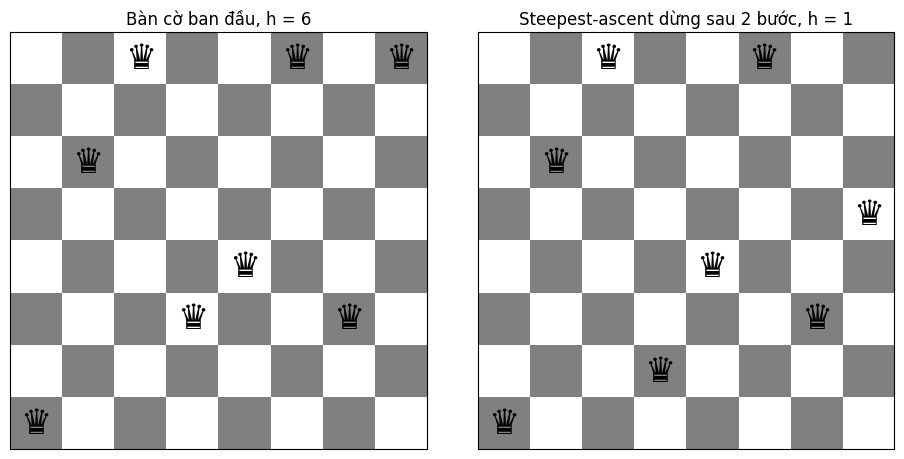

Kiểu dừng: plateau (còn nước đi ngang) | h các láng giềng tốt nhất: 1


In [9]:
# Minh họa một lần mắc kẹt: tìm bàn cờ 8x8 mà steepest-ascent dừng ở h > 0
np.random.seed(11)
for _ in range(1000):
    b0 = random_board(8)
    r0 = steepest_ascent(b0)
    if r0['h'] > 0:
        break
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.6))
draw_board(b0, axes[0], title=f'Bàn cờ ban đầu, h = {conflicts(b0)}')
draw_board(r0['board'], axes[1], title=f"Steepest-ascent dừng sau {r0['steps']} bước, h = {r0['h']}")
plt.tight_layout()
save_fig('nq_04_steepest_ket_o_cuc_tieu_cuc_bo_n8.png')
plt.show()
print('Kiểu dừng:', stuck_type(r0['board']), '| h các láng giềng tốt nhất:',
      min(v[2] for v in neighbor_values(np.array(r0['board']))))

**Nhận xét Task 1.**

* Trên 10 bàn cờ 8×8, steepest-ascent chỉ giải được **1/10**; 9 lượt còn lại dừng ở $h = 1$–$3$ sau 1–4 bước (113–281 lần đánh giá $h$; mỗi bước tốn đúng $n(n-1)=56$ lần đánh giá).
* Trên **500** bàn cờ (Task 6) tỷ lệ thành công là 14,6 % ở $n = 8$ (41,8 % ở $n = 4$), trung bình chỉ khoảng 3 bước. Hướng "chỉ đi xuống" nhanh chóng hết nước cải thiện.
* Điểm đáng chú ý: trong 427 lượt thất bại ở $n=8$, **420 lượt dừng ở plateau** (vẫn còn láng giềng có cùng $h$, tức còn nước đi *ngang*) và chỉ 7 lượt là cực tiểu cục bộ chặt. Hình minh họa là một trường hợp như vậy: bàn cờ dừng ở $h = 1$ và các láng giềng tốt nhất cũng có $h = 1$. Nghĩa là thuật toán bị kẹt vì quy tắc "chỉ nhận nước cải thiện thực sự", không phải vì thực sự hết đường; cho phép một số nước đi ngang là một cách khắc phục quen thuộc.

## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

**Cài đặt.** Vẫn đánh giá toàn bộ $n(n-1)$ láng giềng ở mỗi bước (nên *chi phí giống steepest-ascent*), nhưng chọn **ngẫu nhiên đều** một nước trong *tất cả các nước cải thiện* (không nhất thiết là nước tốt nhất). Dừng khi không còn nước cải thiện.

In [10]:
def inefficient_stochastic_hc(board):
    board = np.array(board)
    h = conflicts(board)
    evals, steps = 1, 0
    trace_h, trace_evals = [h], [evals]
    while h > 0:
        vals = neighbor_values(board)
        evals += len(vals)
        improving = [(c, r, nh) for c, r, nh in vals if nh < h]
        if not improving:                      # không còn nước cải thiện
            break
        c, r, nh = improving[np.random.randint(len(improving))]  # chọn ngẫu nhiên trong các nước cải thiện
        board[c] = r
        h = nh
        steps += 1
        trace_h.append(h)
        trace_evals.append(evals)
    return dict(board=board, h=h, steps=steps, evals=evals, trace_h=trace_h, trace_evals=trace_evals)

np.random.seed(102)
df_t2 = demo_table(inefficient_stochastic_hc, demo_boards)
display(df_t2)
save_table(df_t2, 'nq_task2_ineff_stochastic_10_lan_chay.csv')

,Lần,Bàn cờ ban đầu,h đầu,h cuối,Số bước,Số lần đánh giá h,Kết thúc
0,1,"[7, 3, 1, 6, 7, 7, 5, 3]",8,1,5,337,plateau (còn nước đi ngang)
1,2,"[7, 1, 5, 0, 4, 7, 0, 5]",6,1,5,337,plateau (còn nước đi ngang)
2,3,"[4, 4, 0, 6, 5, 4, 5, 0]",10,0,7,393,nghiệm (h = 0)
3,4,"[1, 3, 7, 2, 0, 3, 5, 3]",6,0,4,225,nghiệm (h = 0)
4,5,"[3, 2, 4, 0, 1, 3, 6, 2]",6,1,5,337,plateau (còn nước đi ngang)
5,6,"[4, 7, 3, 7, 0, 1, 7, 1]",9,0,8,449,nghiệm (h = 0)
6,7,"[7, 0, 6, 4, 3, 3, 4, 7]",9,2,6,393,plateau (còn nước đi ngang)
7,8,"[7, 2, 4, 0, 7, 6, 6, 1]",5,1,3,225,plateau (còn nước đi ngang)
8,9,"[4, 2, 7, 7, 7, 7, 4, 0]",9,2,5,337,plateau (còn nước đi ngang)
9,10,"[4, 2, 4, 1, 0, 3, 3, 7]",6,1,3,225,plateau (còn nước đi ngang)


Đã lưu bảng: results/nq_task2_ineff_stochastic_10_lan_chay.csv


__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

**Nhận xét Task 2.** Vì chọn ngẫu nhiên trong *mọi* nước cải thiện (không phải nước tốt nhất) nên mỗi bước cải thiện ít hơn: trung bình 4,9 bước so với 3,2 bước của steepest ở $n=8$, kéo theo nhiều lần đánh giá hơn (323 so với 227). Chất lượng cuối gần như không đổi (thành công 15,0 % so với 14,6 %; chênh lệch nằm trong sai số lấy mẫu), còn chi phí cao hơn. Mỗi bước vẫn phải đánh giá toàn bộ 56 láng giềng nên đây là thuật toán đắt mà không có lợi thế rõ rệt.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way:

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state.
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

**Chọn ngưỡng dừng $x$ (`patience`).** Có $N = n(n-1)$ nước đi lân cận. Mỗi lần ta lấy mẫu **có hoàn lại** một nước. Xác suất một nước *cụ thể* chưa được lấy trong $x$ lần liên tiếp là $(1-1/N)^x \le e^{-x/N}$. Theo cận hợp (union bound) trên tối đa $N$ nước cải thiện, xác suất bỏ sót *ít nhất một* nước cải thiện còn tồn tại là $\le N e^{-x/N}$. Đặt giá trị này bằng $\delta$ ta được

$$x = \Big\lceil N \ln \frac{N}{\delta} \Big\rceil .$$

Với $\delta = 0.01$: nếu thuật toán dừng sau $x$ lần liên tiếp không cải thiện thì với xác suất $\ge 99\%$ trạng thái hiện tại thực sự không còn nước cải thiện (cực tiểu cục bộ / plateau). $x$ tăng theo $n^2 \ln n$. Ta sẽ kiểm chứng bằng thực nghiệm (tỷ lệ dừng sai).

In [11]:
def patience_for(n, delta=0.01):
    N = n * (n - 1)                              # số láng giềng
    return math.ceil(N * math.log(N / delta))

def efficient_stochastic_hc(board, patience=None):
    board = np.array(board)
    n = len(board)
    h = conflicts(board)
    patience = patience or patience_for(n)
    evals, steps, fails = 1, 0, 0
    trace_h, trace_evals = [h], [evals]
    while h > 0 and fails < patience:             # điều kiện dừng: h = 0 hoặc x lần thử liên tiếp không cải thiện
        c = np.random.randint(n)                  # sinh MỘT láng giềng ngẫu nhiên
        r = np.random.randint(n - 1)
        if r >= board[c]:
            r += 1                                # đảm bảo hàng mới khác hàng cũ
        old = board[c]
        board[c] = r
        nh = conflicts(board)
        evals += 1
        if nh < h:                                # chấp nhận khi cải thiện
            h, steps, fails = nh, steps + 1, 0
            trace_h.append(h)
            trace_evals.append(evals)
        else:
            board[c] = old
            fails += 1
    return dict(board=board, h=h, steps=steps, evals=evals, trace_h=trace_h, trace_evals=trace_evals)

print(pd.DataFrame({'n': [4, 8, 12, 16, 20],
                    'Số láng giềng N = n(n-1)': [n_ * (n_ - 1) for n_ in [4, 8, 12, 16, 20]],
                    'Ngưỡng x (δ = 0,01)': [patience_for(n_) for n_ in [4, 8, 12, 16, 20]]}).to_string(index=False))

np.random.seed(103)
df_t3 = demo_table(efficient_stochastic_hc, demo_boards)
display(df_t3)
save_table(df_t3, 'nq_task3_efficient_stochastic_10_lan_chay.csv')

 n  Số láng giềng N = n(n-1)  Ngưỡng x (δ = 0,01)
 4                        12                   86
 8                        56                  484
12                       132                 1253
16                       240                 2421
20                       380                 4008


,Lần,Bàn cờ ban đầu,h đầu,h cuối,Số bước,Số lần đánh giá h,Kết thúc
0,1,"[7, 3, 1, 6, 7, 7, 5, 3]",8,3,4,497,plateau (còn nước đi ngang)
1,2,"[7, 1, 5, 0, 4, 7, 0, 5]",6,2,3,518,plateau (còn nước đi ngang)
2,3,"[4, 4, 0, 6, 5, 4, 5, 0]",10,2,5,504,plateau (còn nước đi ngang)
3,4,"[1, 3, 7, 2, 0, 3, 5, 3]",6,2,4,518,plateau (còn nước đi ngang)
4,5,"[3, 2, 4, 0, 1, 3, 6, 2]",6,1,4,563,plateau (còn nước đi ngang)
5,6,"[4, 7, 3, 7, 0, 1, 7, 1]",9,2,6,511,plateau (còn nước đi ngang)
6,7,"[7, 0, 6, 4, 3, 3, 4, 7]",9,1,8,585,plateau (còn nước đi ngang)
7,8,"[7, 2, 4, 0, 7, 6, 6, 1]",5,1,4,502,plateau (còn nước đi ngang)
8,9,"[4, 2, 7, 7, 7, 7, 4, 0]",9,2,5,513,plateau (còn nước đi ngang)
9,10,"[4, 2, 4, 1, 0, 3, 3, 7]",6,2,4,535,plateau (còn nước đi ngang)


Đã lưu bảng: results/nq_task3_efficient_stochastic_10_lan_chay.csv


In [12]:
# Kiểm chứng ngưỡng dừng: khi thuật toán dừng với h > 0, có bao nhiêu lần trạng thái đó vẫn còn nước cải thiện?
np.random.seed(104)
false_stops, stuck_runs = 0, 0
kinds = {}
for _ in range(500):
    r = efficient_stochastic_hc(random_board(8))
    if r['h'] > 0:
        stuck_runs += 1
        k = stuck_type(r['board'])
        kinds[k] = kinds.get(k, 0) + 1
        false_stops += (k == 'còn nước cải thiện')
print(f'500 lần chạy (n = 8): {stuck_runs} lần dừng với h > 0; phân loại trạng thái dừng: {kinds}')
print(f'Số lần dừng sai (còn nước cải thiện): {false_stops} / {stuck_runs}')

500 lần chạy (n = 8): 424 lần dừng với h > 0; phân loại trạng thái dừng: {'plateau (còn nước đi ngang)': 419, 'cực tiểu cục bộ chặt': 5}
Số lần dừng sai (còn nước cải thiện): 0 / 424


**Nhận xét Task 3.**

* Ngưỡng dừng tính theo công thức $x = \lceil N\ln(N/\delta)\rceil$ với $\delta = 0{,}01$: $x = 86, 484, 1253, 2421, 4008$ cho $n = 4, 8, 12, 16, 20$.
* **Kiểm chứng:** trong 500 lượt ở $n=8$ có 424 lượt dừng với $h>0$; kiểm tra toàn bộ láng giềng cho thấy **0/424 lần dừng sai** (không lần nào còn nước cải thiện): 419 plateau và 5 cực tiểu chặt. Kết quả phù hợp với bảo đảm $\ge 99\%$ của công thức.
* Chi phí: mỗi lần thử chỉ đánh giá **một** láng giềng, nên tiến bộ ban đầu rất rẻ (trong hình hội tụ, $h$ giảm xuống 1 chỉ sau khoảng 11 lần đánh giá), nhưng phải trả thêm $x$ lần thử để *xác nhận* đã kẹt. Do đó tổng số lần đánh giá trung bình ở $n=8$ (488) vẫn cao hơn steepest (227); lợi thế của biến thể này chỉ rõ khi số láng giềng rất lớn hoặc khi tính $\Delta h$ trong $O(1)$ (xem phần scalability).

## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

**Thiết kế thí nghiệm.** Mỗi *trial* chạy thuật toán từ bàn cờ ngẫu nhiên, dừng ngay khi tìm được $h = 0$, tối đa **100 lần chạy** (1 lần đầu + tối đa 99 lần khởi động lại). Lặp **200 trial** độc lập cho mỗi thuật toán và mỗi $n \in \{4, 8\}$. Ghi nhận: tỷ lệ trial thành công, số lần chạy cần thiết, tổng số lần đánh giá $h$, tổng thời gian.

,n,Thuật toán,Trial thành công (%),Số lần chạy TB,Số lần khởi động lại TB,Số lần chạy lớn nhất,Ước lượng p (1 lần chạy),Số lần đánh giá h TB,Thời gian TB (ms)
0,4,Steepest-ascent HC,100.0,2.290,1.290,11,0.437,61.450,0.490
1,4,Inefficient stochastic HC,100.0,3.095,2.095,14,0.323,99.215,0.458
2,4,Efficient stochastic HC,100.0,3.170,2.170,19,0.315,224.020,1.791
3,8,Steepest-ascent HC,100.0,7.015,6.015,40,0.143,1609.175,11.743
4,8,Inefficient stochastic HC,100.0,7.310,6.310,37,0.137,2374.990,18.104
5,8,Efficient stochastic HC,100.0,7.280,6.280,34,0.137,3531.275,42.894


Đã lưu bảng: results/nq_task4_random_restart.csv


Đã lưu hình: figures/nq_05_random_restart_so_lan_chay_n8.png


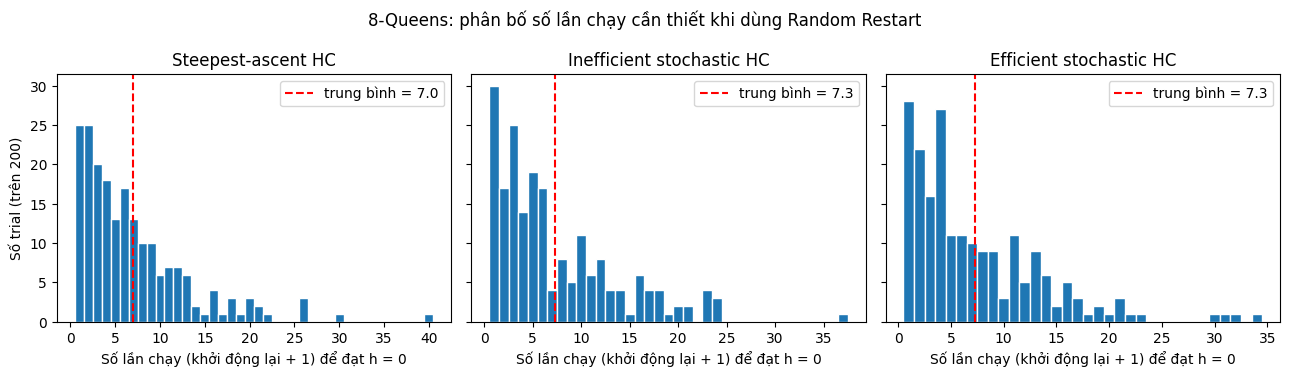

In [13]:
def random_restart(algo, n, max_runs=100, **kw):
    total_evals, best_h = 0, None
    t0 = time.perf_counter()
    for run in range(1, max_runs + 1):
        r = algo(random_board(n), **kw)
        total_evals += r['evals']
        best_h = r['h'] if best_h is None else min(best_h, r['h'])
        if r['h'] == 0:
            break
    return dict(success=(best_h == 0), runs=run, evals=total_evals, best_h=best_h,
                time=time.perf_counter() - t0)

HC_ALGOS = {'Steepest-ascent HC': steepest_ascent,
            'Inefficient stochastic HC': inefficient_stochastic_hc,
            'Efficient stochastic HC': efficient_stochastic_hc}
TRIALS = 200

np.random.seed(2026)
rr_rows, rr_runs = [], {}
for n_ in [4, 8]:
    for name, algo in HC_ALGOS.items():
        res_ = [random_restart(algo, n_) for _ in range(TRIALS)]
        df_ = pd.DataFrame(res_)
        rr_runs[(n_, name)] = df_.runs.values
        p_hat = len(df_) / df_.runs.sum()          # ước lượng xác suất thành công của MỘT lần chạy (hình học)
        rr_rows.append({'n': n_, 'Thuật toán': name,
                        'Trial thành công (%)': 100 * df_.success.mean(),
                        'Số lần chạy TB': df_.runs.mean(),
                        'Số lần khởi động lại TB': df_.runs.mean() - 1,
                        'Số lần chạy lớn nhất': int(df_.runs.max()),
                        'Ước lượng p (1 lần chạy)': p_hat,
                        'Số lần đánh giá h TB': df_.evals.mean(),
                        'Thời gian TB (ms)': 1000 * df_.time.mean()})
df_rr = pd.DataFrame(rr_rows)
display(df_rr.round(3))
save_table(df_rr.round(4), 'nq_task4_random_restart.csv')

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (name, _) in zip(axes, HC_ALGOS.items()):
    runs = rr_runs[(8, name)]
    ax.hist(runs, bins=np.arange(0.5, runs.max() + 1.5, 1), color='tab:blue', edgecolor='white')
    ax.axvline(runs.mean(), color='red', linestyle='--', label=f'trung bình = {runs.mean():.1f}')
    ax.set_title(name); ax.set_xlabel('Số lần chạy (khởi động lại + 1) để đạt h = 0'); ax.legend()
axes[0].set_ylabel('Số trial (trên 200)')
fig.suptitle('8-Queens: phân bố số lần chạy cần thiết khi dùng Random Restart')
plt.tight_layout()
save_fig('nq_05_random_restart_so_lan_chay_n8.png')
plt.show()

**Nhận xét Task 4.**

* Với Random Restart, **cả 200/200 trial của cả ba biến thể đều đạt $h=0$** trong tối đa 100 lần chạy, ở cả $n = 4$ và $n = 8$. Số lần chạy lớn nhất mà một trial cần là 40 (n=8), xa mức 100.
* Số lần chạy trung bình ở $n=8$ là 7,0 (steepest), 7,3 (inefficient) và 7,3 (efficient). Điều này khớp với mô hình hình học: xác suất một lần chạy thành công $p \approx 0{,}14$ cho kỳ vọng $1/p \approx 7$ lần chạy.
* Cả ba biến thể có cùng xác suất thành công mỗi lần chạy nên số lần chạy gần như bằng nhau; khác biệt nằm ở **chi phí**: số lần đánh giá $h$ trung bình là 1 609 (steepest), 2 375 (inefficient), 3 531 (efficient) và thời gian 12 ms, 18 ms, 43 ms. Steepest-ascent rẻ nhất khi $n$ nhỏ vì mỗi bước có ít lần đánh giá và kết thúc sớm.
* Random Restart biến một thuật toán thất bại 85 % thành thuật toán thành công gần như chắc chắn, nhưng bằng cách *nhân chi phí* lên khoảng $1/p$ lần.

## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).

1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

**Cài đặt.** Ở mỗi vòng lặp: sinh một láng giềng ngẫu nhiên, tính $\Delta h = h_{\text{mới}} - h_{\text{cũ}}$. Nếu $\Delta h \le 0$ thì chấp nhận; nếu $\Delta h > 0$ thì chấp nhận với xác suất

$$p = e^{-\Delta h / T},$$

trong đó nhiệt độ $T = T(t)$ giảm dần theo *lịch làm nguội*. $T$ lớn: gần như chấp nhận mọi nước (khám phá); $T \to 0$: chỉ chấp nhận nước tốt hơn (khai thác). Thuật toán dừng khi $h = 0$ hoặc hết `max_iters` vòng; kết quả trả về là **bàn cờ tốt nhất đã gặp**. Các lịch làm nguội được thử:

| Lịch | Công thức |
|---|---|
| Hình học (geometric) | $T(t) = T_0 \, \alpha^{t}$ với $\alpha = 0{,}99$ và $\alpha = 0{,}999$ |
| Tuyến tính (linear) | $T(t) = T_0\,(1 - t / t_{\max})$ |
| Logarit | $T(t) = T_0 / \ln(t + 2)$ |

Với bài toán này $\Delta h$ thường là các số nguyên nhỏ (1–4) nên $T_0 \approx 2$ là hợp lý (ở $T=2$ nước đi tệ hơn $\Delta h=1$ được chấp nhận với xác suất ≈ 61 %; ở $T=0.2$ chỉ ≈ 0,7 %).

In [14]:
def sched_geometric(T0, alpha): return lambda t: T0 * alpha ** t
def sched_linear(T0, max_iters): return lambda t: T0 * (1 - t / max_iters)
def sched_log(T0): return lambda t: T0 / math.log(t + 2)

def simulated_annealing(board, schedule, max_iters=5000, record=False):
    board = np.array(board)
    n = len(board)
    h = conflicts(board)
    best_h, best_board = h, board.copy()
    evals, steps = 1, 0
    trace_h, trace_evals = [h], [evals]
    hist = [h] if record else None
    for t in range(max_iters):
        if h == 0:
            break
        T = schedule(t)
        c = np.random.randint(n)                   # một láng giềng ngẫu nhiên
        r = np.random.randint(n - 1)
        if r >= board[c]:
            r += 1
        old = board[c]
        board[c] = r
        nh = conflicts(board)
        evals += 1
        dh = nh - h
        if dh <= 0 or (T > 0 and np.random.rand() < math.exp(-dh / T)):   # chấp nhận nước tệ hơn với xác suất e^(-dh/T)
            h = nh
            steps += 1
            trace_h.append(h)
            trace_evals.append(evals)
            if h < best_h:
                best_h, best_board = h, board.copy()
        else:
            board[c] = old
        if record:
            hist.append(h)
    return dict(board=best_board, h=best_h, final_h=h, steps=steps, evals=evals,
                trace_h=trace_h, trace_evals=trace_evals, hist=hist)

MAX_ITERS = 5000
SCHEDULES = {
    'Hình học T0=2, α=0,99':  sched_geometric(2, 0.99),
    'Hình học T0=2, α=0,999': sched_geometric(2, 0.999),
    'Tuyến tính T0=2':         sched_linear(2, MAX_ITERS),
    'Logarit T0=2':            sched_log(2),
}

# Thí nghiệm: 100 bàn cờ 8x8 ngẫu nhiên, cùng bộ bàn cờ cho mọi lịch làm nguội
np.random.seed(2051)
boards_sa = [random_board(8) for _ in range(100)]
sa_rows, sa_hist = [], {}
np.random.seed(2052)
for name, sch in SCHEDULES.items():
    res_, t_list = [], []
    for b in boards_sa:
        t0 = time.perf_counter()
        r = simulated_annealing(b, sch, MAX_ITERS, record=True)
        t_list.append(time.perf_counter() - t0)
        res_.append(r)
    hists = np.zeros((len(res_), MAX_ITERS + 1))
    for i, r in enumerate(res_):
        hh = np.array(r['hist'])
        hists[i, :len(hh)] = hh
        hists[i, len(hh):] = hh[-1]              # sau khi dừng, h giữ nguyên giá trị cuối
    sa_hist[name] = hists
    sa_rows.append({'Lịch làm nguội': name,
                    'Thành công (%)': 100 * np.mean([r['h'] == 0 for r in res_]),
                    'h tốt nhất TB': np.mean([r['h'] for r in res_]),
                    'h cuối TB': np.mean([r['final_h'] for r in res_]),
                    'Số vòng lặp TB': np.mean([r['evals'] - 1 for r in res_]),
                    'Thời gian TB (ms)': 1000 * np.mean(t_list)})
df_sa = pd.DataFrame(sa_rows)
display(df_sa.round(3))
save_table(df_sa.round(4), 'nq_task5_sa_so_sanh_lich_lam_nguoi_n8.csv')

,Lịch làm nguội,Thành công (%),h tốt nhất TB,h cuối TB,Số vòng lặp TB,Thời gian TB (ms)
0,"Hình học T0=2, α=0,99",98.0,0.02,0.02,804.60,9.601
1,"Hình học T0=2, α=0,999",98.0,0.02,0.02,1625.49,21.116
2,Tuyến tính T0=2,89.0,0.11,0.11,3393.96,41.080
3,Logarit T0=2,100.0,0.00,0.00,709.62,9.564


Đã lưu bảng: results/nq_task5_sa_so_sanh_lich_lam_nguoi_n8.csv


Đã lưu hình: figures/nq_06_sa_lich_lam_nguoi_n8.png


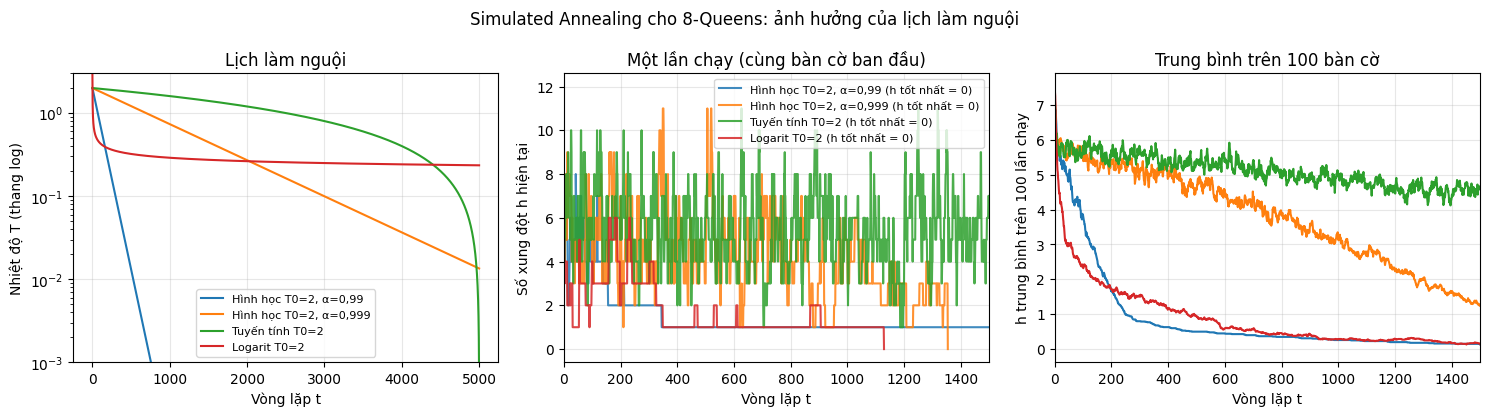

In [15]:
# Trực quan hóa quá trình tìm kiếm: nhiệt độ, một lần chạy cụ thể và trung bình trên 100 lần chạy
np.random.seed(2053)
b_vis = boards_sa[0]
ts = np.arange(MAX_ITERS)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for name, sch in SCHEDULES.items():
    axes[0].plot(ts, [sch(t) for t in ts], label=name)
    r = simulated_annealing(b_vis, sch, MAX_ITERS, record=True)
    axes[1].plot(r['hist'], label=f"{name} (h tốt nhất = {r['h']})", alpha=0.85)
    axes[2].plot(sa_hist[name].mean(axis=0), label=name)
axes[0].set_yscale('log'); axes[0].set_ylim(1e-3, 3)
axes[0].set_xlabel('Vòng lặp t'); axes[0].set_ylabel('Nhiệt độ T (thang log)'); axes[0].set_title('Lịch làm nguội')
axes[1].set_xlabel('Vòng lặp t'); axes[1].set_ylabel('Số xung đột h hiện tại')
axes[1].set_title('Một lần chạy (cùng bàn cờ ban đầu)'); axes[1].set_xlim(0, 1500)
axes[2].set_xlabel('Vòng lặp t'); axes[2].set_ylabel('h trung bình trên 100 lần chạy')
axes[2].set_title('Trung bình trên 100 bàn cờ'); axes[2].set_xlim(0, 1500)
for ax in axes: ax.grid(True, alpha=0.3)
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
fig.suptitle('Simulated Annealing cho 8-Queens: ảnh hưởng của lịch làm nguội')
plt.tight_layout()
save_fig('nq_06_sa_lich_lam_nguoi_n8.png')
plt.show()

In [16]:
# Độ nhạy theo nhiệt độ ban đầu T0 (lịch hình học alpha = 0,995), cùng 100 bàn cờ
np.random.seed(2054)
rows = []
for T0 in [0.2, 0.5, 1, 2, 5, 10]:
    sch = sched_geometric(T0, 0.995)
    res_ = [simulated_annealing(b, sch, MAX_ITERS) for b in boards_sa]
    rows.append({'T0': T0, 'Thành công (%)': 100 * np.mean([r['h'] == 0 for r in res_]),
                 'h tốt nhất TB': np.mean([r['h'] for r in res_]),
                 'Số vòng lặp TB': np.mean([r['evals'] - 1 for r in res_])})
df_t0 = pd.DataFrame(rows)
display(df_t0.round(3))
save_table(df_t0.round(4), 'nq_task5_sa_do_nhay_T0.csv')

# Chọn lịch làm nguội dùng cho các so sánh sau: thành công cao nhất, hòa thì ít vòng lặp nhất
best_name = df_sa.sort_values(['Thành công (%)', 'Số vòng lặp TB'], ascending=[False, True]).iloc[0]['Lịch làm nguội']
SA_SCHEDULE = SCHEDULES[best_name]
print('Lịch làm nguội được chọn cho Task 6 và phần scalability:', best_name)

,T0,Thành công (%),h tốt nhất TB,Số vòng lặp TB
0,0.2,96.0,0.04,648.66
1,0.5,98.0,0.02,801.94
2,1.0,97.0,0.03,853.31
3,2.0,94.0,0.06,1046.75
4,5.0,98.0,0.02,1135.71
5,10.0,96.0,0.04,1429.42


Đã lưu bảng: results/nq_task5_sa_do_nhay_T0.csv
Lịch làm nguội được chọn cho Task 6 và phần scalability: Logarit T0=2


**Nhận xét Task 5** (100 bàn cờ 8×8, tối đa 5 000 vòng lặp).

* Mọi lịch làm nguội đều vượt hẳn Hill Climbing (steepest chỉ 14,6 %): hình học $\alpha=0{,}99$: 98 %, $\alpha=0{,}999$: 98 %, tuyến tính: 89 %, **logarit: 100 %** (trung bình 710 vòng lặp). Vì logarit có thành công cao nhất và ít vòng lặp nhất nên được chọn cho Task 6.
* *Tại sao?* Với $\Delta h = 1$, xác suất chấp nhận $e^{-1/T}$ là 61 % ở $T=2$, 3,6 % ở $T=0{,}3$ và gần 0 ở $T<0{,}05$. Lịch logarit giảm rất nhanh lúc đầu rồi **ở lại vùng $T \approx 0{,}25$–$0{,}4$** lâu: đủ ấm để thỉnh thoảng vượt rào cản $\Delta h = 1$–$2$, đủ lạnh để không đi lang thang ngẫu nhiên. Lịch tuyến tính và hình học $\alpha=0{,}999$ giữ $T$ cao quá lâu (đường trung bình trong hình còn quanh 4–5 sau 1 500 vòng, tức là chủ yếu đi ngẫu nhiên) nên tốn nhiều vòng lặp và có lượt chưa giải xong khi hết 5 000 vòng. Lịch hình học $\alpha=0{,}99$ nguội quá nhanh ($T<0{,}02$ sau khoảng 400 vòng) nên đôi khi "đóng băng" ở $h = 1$.
* Độ nhạy theo $T_0$ (lịch hình học $\alpha = 0{,}995$): tỷ lệ thành công 94–98 % với $T_0 \in [0{,}2;\ 10]$ – khác biệt nằm trong sai số lấy mẫu của 100 lần chạy – nhưng số vòng lặp tăng gần gấp đôi (649 → 1 429) khi $T_0$ lớn, vì phần đầu chỉ là đi ngẫu nhiên. Điều quan trọng là *vùng nhiệt độ trung gian* và tốc độ nguội, hơn là giá trị $T_0$ chính xác.

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

**Thiết kế.** Mỗi $n \in \{4, 8\}$: **500 bàn cờ khởi tạo khác nhau** (≥ 100 theo yêu cầu), *cùng bộ bàn cờ* cho mọi thuật toán (so sánh ghép cặp). Mỗi thuật toán chạy **một lần** từ mỗi bàn cờ (không khởi động lại); thời gian đo riêng cho từng lần chạy. Điều kiện dừng: Steepest/Inefficient – không còn nước cải thiện; Efficient stochastic – ngưỡng `patience_for(n)`; Simulated Annealing – `max_iters = 5000` hoặc $h = 0$. "Tối ưu" nghĩa là $h = 0$.

In [17]:
N_RUNS = 500
ALGOS6 = {'Steepest asc. HC': steepest_ascent,
          'Ineff. Stochastic HC': inefficient_stochastic_hc,
          'Efficient Stochastic HC': efficient_stochastic_hc,
          'Simulated Annealing': lambda b: simulated_annealing(b, SA_SCHEDULE, MAX_ITERS)}

def run_many(algo, boards):
    rows = []
    for b in boards:
        t0 = time.perf_counter()
        r = algo(b)
        dt = time.perf_counter() - t0
        rows.append({'h': r['h'], 'steps': r['steps'], 'evals': r['evals'], 'time': dt, 'board': r['board']})
    return pd.DataFrame(rows)

runs6 = {}
t_start = time.perf_counter()
for n_ in [4, 8]:
    np.random.seed(6000 + n_)
    boards6 = [random_board(n_) for _ in range(N_RUNS)]           # cùng bộ bàn cờ cho mọi thuật toán
    for name, algo in ALGOS6.items():
        np.random.seed(7000 + n_)                                 # cùng hạt giống cho phần ngẫu nhiên của thuật toán
        runs6[(n_, name)] = run_many(algo, boards6)
    runs6[(n_, 'boards')] = boards6
print(f'Hoàn tất {N_RUNS} lượt x 4 thuật toán x 2 cỡ bàn cờ trong {time.perf_counter() - t_start:.1f} s')

rows = []
for n_ in [4, 8]:
    for name in ALGOS6:
        d = runs6[(n_, name)]
        rows.append({'Algorithm': name, 'Board size': n_,
                     'Avg. Run time (ms)': 1000 * d.time.mean(),
                     'Avg. number of conflicts': d.h.mean(),
                     '% of runs ending in optimal solution': 100 * (d.h == 0).mean(),
                     'Avg. steps': d.steps.mean(), 'Avg. evals of h': d.evals.mean()})
df_t6 = pd.DataFrame(rows)
display(df_t6.round(3))
save_table(df_t6.round(4), 'nq_task6_bang_so_sanh_n4_n8.csv')

Hoàn tất 500 lượt x 4 thuật toán x 2 cỡ bàn cờ trong 10.0 s


,Algorithm,Board size,Avg. Run time (ms),Avg. number of conflicts,% of runs ending in optimal solution,Avg. steps,Avg. evals of h
0,Steepest asc. HC,4,0.121,0.654,41.8,1.546,26.536
1,Ineff. Stochastic HC,4,0.138,0.794,35.4,1.868,31.168
2,Efficient Stochastic HC,4,0.590,0.788,34.6,1.850,67.648
3,Simulated Annealing,4,0.590,0.000,100.0,20.320,48.746
4,Steepest asc. HC,8,1.641,1.256,14.6,3.188,227.352
5,Ineff. Stochastic HC,8,2.342,1.274,15.0,4.908,323.448
6,Efficient Stochastic HC,8,5.500,1.348,12.8,4.758,487.638
7,Simulated Annealing,8,9.144,0.002,99.8,114.632,751.114


Đã lưu bảng: results/nq_task6_bang_so_sanh_n4_n8.csv


,n,Thuật toán,Số lượt thất bại,Cực tiểu cục bộ chặt,Plateau (còn nước đi ngang),Còn nước cải thiện (dừng sai),h cuối trung bình (lượt thất bại)
0,4,Steepest asc. HC,291,0,291,0,1.124
1,4,Ineff. Stochastic HC,323,0,323,0,1.229
2,4,Efficient Stochastic HC,327,0,327,0,1.205
3,8,Steepest asc. HC,427,7,420,0,1.471
4,8,Ineff. Stochastic HC,425,4,421,0,1.499
5,8,Efficient Stochastic HC,436,6,430,0,1.546


Đã lưu bảng: results/nq_task6_phan_tich_ket_o_local_optimum.csv


Đã lưu hình: figures/nq_07_so_sanh_thanh_cong_thoi_gian_h.png


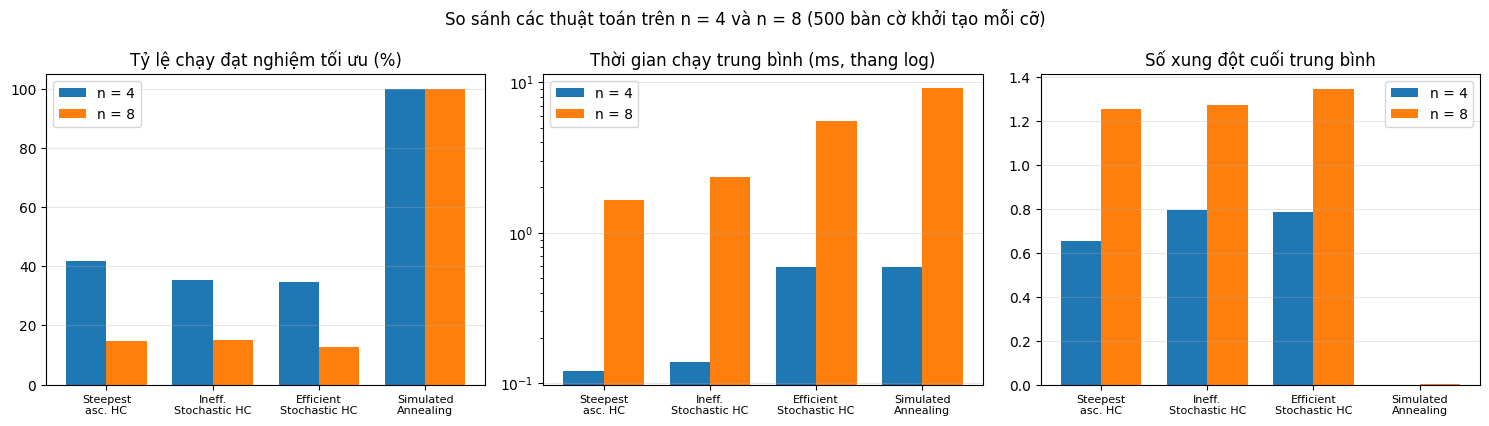

In [18]:
# Phân tích mắc kẹt: các lượt thất bại (h > 0) của 3 biến thể Hill Climbing dừng ở cực tiểu cục bộ chặt hay ở plateau?
rows = []
for n_ in [4, 8]:
    for name in ['Steepest asc. HC', 'Ineff. Stochastic HC', 'Efficient Stochastic HC']:
        d = runs6[(n_, name)]
        failed = d[d.h > 0]
        kinds = failed.board.apply(stuck_type).value_counts()
        rows.append({'n': n_, 'Thuật toán': name, 'Số lượt thất bại': len(failed),
                     'Cực tiểu cục bộ chặt': int(kinds.get('cực tiểu cục bộ chặt', 0)),
                     'Plateau (còn nước đi ngang)': int(kinds.get('plateau (còn nước đi ngang)', 0)),
                     'Còn nước cải thiện (dừng sai)': int(kinds.get('còn nước cải thiện', 0)),
                     'h cuối trung bình (lượt thất bại)': failed.h.mean() if len(failed) else 0})
df_stuck = pd.DataFrame(rows)
display(df_stuck.round(3))
save_table(df_stuck.round(4), 'nq_task6_phan_tich_ket_o_local_optimum.csv')

# Biểu đồ so sánh: tỷ lệ thành công, thời gian, h cuối trung bình
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
x = np.arange(len(ALGOS6)); w = 0.38
for j, n_ in enumerate([4, 8]):
    d6 = df_t6[df_t6['Board size'] == n_]
    off = (j - 0.5) * w
    axes[0].bar(x + off, d6['% of runs ending in optimal solution'], w, label=f'n = {n_}')
    axes[1].bar(x + off, d6['Avg. Run time (ms)'], w, label=f'n = {n_}')
    axes[2].bar(x + off, d6['Avg. number of conflicts'], w, label=f'n = {n_}')
titles = ['Tỷ lệ chạy đạt nghiệm tối ưu (%)', 'Thời gian chạy trung bình (ms, thang log)', 'Số xung đột cuối trung bình']
for ax, t in zip(axes, titles):
    ax.set_xticks(x); ax.set_xticklabels([k.replace(' ', '\n', 1) for k in ALGOS6], fontsize=8)
    ax.set_title(t); ax.legend(); ax.grid(True, axis='y', alpha=0.3)
axes[1].set_yscale('log')
fig.suptitle(f'So sánh các thuật toán trên n = 4 và n = 8 ({N_RUNS} bàn cờ khởi tạo mỗi cỡ)')
plt.tight_layout()
save_fig('nq_07_so_sanh_thanh_cong_thoi_gian_h.png')
plt.show()

**Nhận xét Task 6 – bảng so sánh** (500 bàn cờ khởi tạo mỗi cỡ).

* **Tỷ lệ tối ưu:** ở $n=8$: steepest 14,6 %, inefficient 15,0 %, efficient 12,8 %, **Simulated Annealing 99,8 %**; ở $n=4$: 41,8 %, 35,4 %, 34,6 % và 100 %. Ba biến thể Hill Climbing không khác nhau đáng kể (sai số chuẩn khoảng 1,6 điểm phần trăm ở $n=8$); SA khác biệt hoàn toàn.
* **Xung đột cuối trung bình:** khoảng 1,26–1,35 (Hill Climbing) so với 0,002 (SA) ở $n=8$.
* **Thời gian:** SA chậm hơn steepest khoảng 5–6 lần (9,1 ms so với 1,6 ms ở $n=8$; 751 so với 227 lần đánh giá $h$), nhưng thành công gần như chắc chắn. Efficient stochastic HC (5,5 ms) chậm hơn steepest vì còn phải trả `patience` lần thử để xác nhận đã kẹt.
* **Mắc kẹt:** hầu hết các lượt thất bại (n=8: 420/427, 421/425, 430/436) dừng ở **plateau** (còn nước đi ngang), chỉ một số ít ở cực tiểu cục bộ chặt; ở $n=4$ toàn bộ lượt thất bại là plateau. Số xung đột cuối của các lượt thất bại chỉ khoảng 1,1–1,5: các thuật toán thường dừng rất gần nghiệm nhưng không thể đi tiếp.
* Phân biệt **thành công** ($h = 0$) với **nghiệm tốt nhất** (h nhỏ nhất): Hill Climbing thất bại vẫn trả về nghiệm tốt ($h=1$–$2$), nhưng không hợp lệ.

### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

Ta chọn **một bàn cờ 8×8 mà steepest-ascent bị kẹt** (bàn cờ đầu tiên trong bộ 500 bàn cờ có tính chất đó) rồi chạy cả bốn thuật toán từ **chính bàn cờ này**; đây là một lượt chạy *đại diện có chủ đích* cho trường hợp khó, không phải lượt trung bình. Biểu đồ (a) vẽ $h$ theo số lần đánh giá hàm mục tiêu (thang log) – thước đo chi phí công bằng giữa các thuật toán; biểu đồ (b) vẽ $h$ theo số nước đi được chấp nhận.

Bàn cờ minh họa: chỉ số 0 trong bộ 500 bàn cờ, h đầu = 6, board = [1, 6, 7, 0, 5, 0, 6, 4]
Steepest asc. HC          : h cuối = 1, số bước chấp nhận = 3, số lần đánh giá h = 225
Ineff. Stochastic HC      : h cuối = 2, số bước chấp nhận = 4, số lần đánh giá h = 281
Efficient Stochastic HC   : h cuối = 1, số bước chấp nhận = 5, số lần đánh giá h = 495
Simulated Annealing       : h cuối = 0, số bước chấp nhận = 92, số lần đánh giá h = 349


Đã lưu hình: figures/nq_08_hoi_tu_n8.png


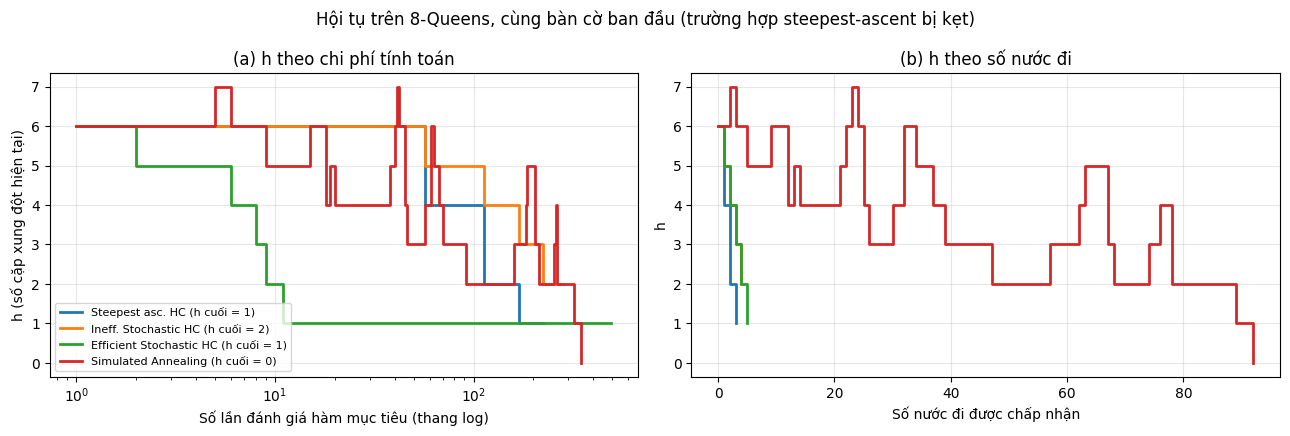

In [19]:
boards8 = runs6[(8, 'boards')]
idx_hard = next(i for i in range(N_RUNS) if runs6[(8, 'Steepest asc. HC')].h.iloc[i] > 0)
b_conv = boards8[idx_hard]
print(f'Bàn cờ minh họa: chỉ số {idx_hard} trong bộ 500 bàn cờ, h đầu = {conflicts(b_conv)}, board = {list(map(int, b_conv))}')

np.random.seed(8001)
conv = {name: algo(b_conv) for name, algo in ALGOS6.items()}
for name, r in conv.items():
    print(f"{name:26s}: h cuối = {r['h']}, số bước chấp nhận = {r['steps']}, số lần đánh giá h = {r['evals']}")

markers = {'Steepest asc. HC': 'tab:blue', 'Ineff. Stochastic HC': 'tab:orange',
           'Efficient Stochastic HC': 'tab:green', 'Simulated Annealing': 'tab:red'}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for name, r in conv.items():
    xs = list(r['trace_evals']) + [r['evals']]
    ys = list(r['trace_h']) + [r['trace_h'][-1]]
    axes[0].step(xs, ys, where='post', label=f"{name} (h cuối = {r['trace_h'][-1]})", color=markers[name], linewidth=2)
    axes[1].step(range(len(r['trace_h'])), r['trace_h'], where='post', label=name, color=markers[name], linewidth=2)
axes[0].set_xscale('log'); axes[0].set_xlabel('Số lần đánh giá hàm mục tiêu (thang log)')
axes[0].set_ylabel('h (số cặp xung đột hiện tại)'); axes[0].set_title('(a) h theo chi phí tính toán')
axes[1].set_xlabel('Số nước đi được chấp nhận'); axes[1].set_ylabel('h'); axes[1].set_title('(b) h theo số nước đi')
for ax in axes: ax.grid(True, alpha=0.3)
axes[0].legend(fontsize=8)
fig.suptitle('Hội tụ trên 8-Queens, cùng bàn cờ ban đầu (trường hợp steepest-ascent bị kẹt)')
plt.tight_layout()
save_fig('nq_08_hoi_tu_n8.png')
plt.show()

**Nhận xét hội tụ** (bàn cờ minh họa có $h = 6$, board = `[1, 6, 7, 0, 5, 0, 6, 4]`; đây là lượt chọn có chủ đích vì steepest-ascent bị kẹt, không phải lượt trung bình).

* **Hill Climbing (3 biến thể):** giảm $h$ nhanh ngay từ đầu rồi *phẳng hẳn*: steepest xuống $h = 1$ sau 3 bước (225 lần đánh giá), inefficient dừng ở $h = 2$ sau 4 bước, efficient dừng ở $h = 1$ sau 5 bước chấp nhận (495 lần đánh giá). Phần lớn chi phí của efficient là đoạn "nằm ngang" cuối cùng, chờ hết `patience`.
* Theo **chi phí tính toán** (biểu đồ a), efficient stochastic HC giảm $h$ nhanh nhất trong những lần đánh giá đầu (đạt $h=1$ sau khoảng 11 lần đánh giá) vì mỗi bước chỉ tốn một lần đánh giá, trong khi steepest cần 56 lần cho mỗi bước.
* **Simulated Annealing:** quỹ đạo *không đơn điệu*; $h$ có lúc tăng lên 7 (nhiệt độ cao chấp nhận nước đi tệ), rồi thấp dần, và đạt $h=0$ sau 92 nước đi chấp nhận (349 lần đánh giá). Chấp nhận có kiểm soát các nước đi tệ hơn chính là cách thoát khỏi plateau/cực tiểu cục bộ mà ba biến thể kia mắc kẹt.
* Cả ba biến thể Hill Climbing đều **kẹt thường xuyên** (hơn 85 % lượt chạy ở $n=8$, chủ yếu ở plateau); SA hầu như không kẹt.

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

Ngoài bốn thuật toán, ta thêm một biến thể **Efficient stochastic HC với tính độ chênh $\Delta h$ trong $O(1)$**: giữ sẵn số quân trên mỗi hàng/đường chéo và chỉ cập nhật khi chấp nhận nước đi, thay vì gọi lại `conflicts` ($O(n)$) cho mỗi láng giềng. Đây là cùng một thuật toán, chỉ khác **cài đặt**, để thấy độ phức tạp thực nghiệm phụ thuộc vào cách cài đặt như thế nào. Mỗi điểm là trung bình **30 lượt chạy** từ cùng bộ bàn cờ khởi tạo; $n = 4, 8, 12, 16, 20$.

In [20]:
def efficient_stochastic_hc_delta(board, patience=None):
    """Cùng thuật toán Efficient stochastic HC, nhưng tính Delta h trong O(1) bằng bộ đếm hàng/đường chéo."""
    b = [int(v) for v in board]
    n = len(b)
    patience = patience or patience_for(n)
    row, d1, d2 = [0] * n, [0] * (2 * n), [0] * (2 * n)
    for i in range(n):
        row[b[i]] += 1; d1[i + b[i]] += 1; d2[i - b[i] + n] += 1
    h = sum(comb2(v) for v in row + d1 + d2)
    evals, steps, fails = 1, 0, 0
    while h > 0 and fails < patience:
        c = np.random.randint(n)
        r = np.random.randint(n - 1)
        old = b[c]
        if r >= old:
            r += 1
        # độ chênh h khi chuyển quân ở cột c từ hàng old sang hàng r (tính O(1))
        removed = (row[old] - 1) + (d1[c + old] - 1) + (d2[c - old + n] - 1)
        added = row[r] + d1[c + r] + d2[c - r + n]
        dh = added - removed
        evals += 1
        if dh < 0:
            row[old] -= 1; d1[c + old] -= 1; d2[c - old + n] -= 1
            row[r] += 1;   d1[c + r] += 1;   d2[c - r + n] += 1
            b[c] = r
            h += dh
            steps += 1
            fails = 0
        else:
            fails += 1
    return dict(board=np.array(b), h=h, steps=steps, evals=evals, trace_h=[h], trace_evals=[evals])

# Kiểm tra tính đúng đắn: Delta h tính O(1) phải bằng conflicts(mới) - conflicts(cũ)
np.random.seed(9)
for _ in range(2000):
    n_ = np.random.randint(4, 21)
    b_ = random_board(n_)
    c_ = np.random.randint(n_); r_ = np.random.randint(n_)
    if r_ == b_[c_]:
        continue
    row_, d1_, d2_ = [0] * n_, [0] * (2 * n_), [0] * (2 * n_)
    for i in range(n_):
        row_[b_[i]] += 1; d1_[i + b_[i]] += 1; d2_[i - b_[i] + n_] += 1
    old_ = b_[c_]
    dh_fast = (row_[r_] + d1_[c_ + r_] + d2_[c_ - r_ + n_]) - ((row_[old_] - 1) + (d1_[c_ + old_] - 1) + (d2_[c_ - old_ + n_] - 1))
    b2 = b_.copy(); b2[c_] = r_
    assert dh_fast == conflicts(b2) - conflicts(b_)
print('Công thức Delta h O(1) khớp conflicts() trên 2000 phép thử ngẫu nhiên.')
r_chk = efficient_stochastic_hc_delta(random_board(8))
assert conflicts(r_chk['board']) == r_chk['h']

Công thức Delta h O(1) khớp conflicts() trên 2000 phép thử ngẫu nhiên.


Đã lưu bảng: results/nq_task6_scalability_thoi_gian_theo_n.csv


n,4,8,12,16,20
Thuật toán,,,,,
Steepest asc. HC,0.117,1.581,10.666,22.687,55.888
Ineff. Stochastic HC,0.147,2.126,13.707,34.312,98.709
Efficient Stochastic HC,0.521,5.051,19.049,52.680,93.598
Efficient Stochastic HC (Δh O(1)),0.256,1.652,4.861,10.396,16.528
Simulated Annealing,0.409,8.651,48.974,121.325,185.613


**Thành công (%) theo n**

n,4,8,12,16,20
Thuật toán,,,,,
Steepest asc. HC,43.3,3.3,6.7,6.7,3.3
Ineff. Stochastic HC,46.7,16.7,0.0,3.3,3.3
Efficient Stochastic HC,40.0,20.0,3.3,0.0,3.3
Efficient Stochastic HC (Δh O(1)),40.0,20.0,3.3,0.0,3.3
Simulated Annealing,100.0,100.0,100.0,100.0,90.0


**Số lần đánh giá hàm mục tiêu trung bình theo n**

n,4,8,12,16,20
Thuật toán,,,,,
Steepest asc. HC,26.0,223.0,771.0,1809.0,3446.0
Ineff. Stochastic HC,31.0,305.0,1202.0,2737.0,5815.0
Efficient Stochastic HC,65.0,441.0,1374.0,2837.0,4484.0
Efficient Stochastic HC (Δh O(1)),65.0,441.0,1374.0,2837.0,4484.0
Simulated Annealing,47.0,733.0,3067.0,6466.0,8690.0


Đã lưu hình: figures/nq_09_log_log_thoi_gian_theo_n.png


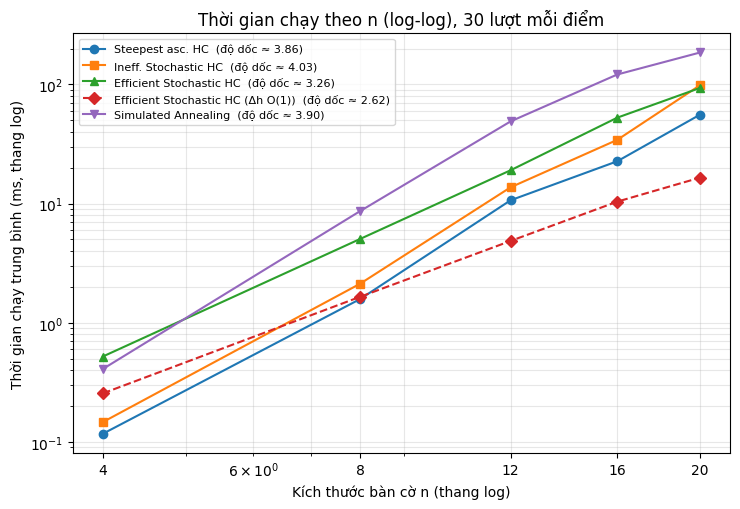

,Thuật toán,Số mũ thực nghiệm k (t ~ n^k)
0,Steepest asc. HC,3.86
1,Ineff. Stochastic HC,4.03
2,Efficient Stochastic HC,3.26
3,Efficient Stochastic HC (Δh O(1)),2.62
4,Simulated Annealing,3.90


Đã lưu bảng: results/nq_task6_so_mu_thuc_nghiem.csv


In [21]:
SIZES = [4, 8, 12, 16, 20]
RUNS_SCAL = 30
SCAL_ALGOS = {
    'Steepest asc. HC': steepest_ascent,
    'Ineff. Stochastic HC': inefficient_stochastic_hc,
    'Efficient Stochastic HC': efficient_stochastic_hc,
    'Efficient Stochastic HC (Δh O(1))': efficient_stochastic_hc_delta,
    'Simulated Annealing': lambda b: simulated_annealing(b, SA_SCHEDULE, 20000),
}
scal_rows = []
for n_ in SIZES:
    np.random.seed(9000 + n_)
    boards_s = [random_board(n_) for _ in range(RUNS_SCAL)]
    for name, algo in SCAL_ALGOS.items():
        np.random.seed(9500 + n_)
        d = run_many(algo, boards_s)
        scal_rows.append({'n': n_, 'Thuật toán': name, 'Thời gian TB (ms)': 1000 * d.time.mean(),
                          'Thành công (%)': 100 * (d.h == 0).mean(), 'Số lần đánh giá h TB': d.evals.mean()})
df_scal = pd.DataFrame(scal_rows)
save_table(df_scal.round(4), 'nq_task6_scalability_thoi_gian_theo_n.csv')
display(df_scal.pivot(index='Thuật toán', columns='n', values='Thời gian TB (ms)').reindex(list(SCAL_ALGOS)).round(3))
display(Markdown('**Thành công (%) theo n**'))
display(df_scal.pivot(index='Thuật toán', columns='n', values='Thành công (%)').reindex(list(SCAL_ALGOS)).round(1))
display(Markdown('**Số lần đánh giá hàm mục tiêu trung bình theo n**'))
display(df_scal.pivot(index='Thuật toán', columns='n', values='Số lần đánh giá h TB').reindex(list(SCAL_ALGOS)).round(0))

# Ước lượng bậc thực nghiệm: hồi quy tuyến tính log(t) = a + k log(n)  ->  t ~ n^k
slopes = {}
fig, ax = plt.subplots(figsize=(7.5, 5.2))
styles = ['o-', 's-', '^-', 'D--', 'v-']
for (name, _), st in zip(SCAL_ALGOS.items(), styles):
    d = df_scal[df_scal['Thuật toán'] == name].sort_values('n')
    k, a = np.polyfit(np.log(d['n']), np.log(d['Thời gian TB (ms)']), 1)
    slopes[name] = k
    ax.loglog(d['n'], d['Thời gian TB (ms)'], st, label=f'{name}  (độ dốc ≈ {k:.2f})')
ax.set_xticks(SIZES); ax.set_xticklabels(SIZES)
ax.set_xlabel('Kích thước bàn cờ n (thang log)'); ax.set_ylabel('Thời gian chạy trung bình (ms, thang log)')
ax.set_title('Thời gian chạy theo n (log-log), 30 lượt mỗi điểm')
ax.grid(True, which='both', alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout()
save_fig('nq_09_log_log_thoi_gian_theo_n.png')
plt.show()
df_slopes = pd.DataFrame({'Thuật toán': list(slopes), 'Số mũ thực nghiệm k (t ~ n^k)': [round(v, 2) for v in slopes.values()]})
display(df_slopes)
save_table(df_slopes, 'nq_task6_so_mu_thuc_nghiem.csv')

**Nhận xét khả năng mở rộng** (30 lượt mỗi điểm, $n = 4,\dots,20$; thời gian là thời gian chạy đến khi thuật toán dừng, dù thành công hay không).

| Thuật toán | Số mũ thực nghiệm $k$ ($t \sim n^k$) | Giải thích lý thuyết |
|---|---|---|
| Steepest asc. HC | 3,86 | $n^2$ láng giềng × $O(n)$ cho mỗi lần gọi `conflicts` × $O(n)$ bước ⇒ $\approx n^4$ |
| Ineff. Stochastic HC | 4,03 | cùng chi phí mỗi bước như steepest ⇒ $\approx n^4$ |
| Efficient Stochastic HC | 3,26 | $x \approx n^2\ln n$ lần thử × $O(n)$ mỗi lần ⇒ $\approx n^3\ln n$ |
| Efficient Stochastic HC ($\Delta h$ $O(1)$) | 2,62 | cùng thuật toán nhưng mỗi lần thử $O(1)$ ⇒ $\approx n^2\ln n$ (thực tế còn chi phí cố định của Python) |
| Simulated Annealing | 3,90 | số vòng lặp tăng theo $n$ × $O(n)$ mỗi vòng; số mũ bị ảnh hưởng bởi trần 20 000 vòng (10 % lượt ở $n=20$ chưa giải xong) |

* Cùng một thuật toán Efficient Stochastic HC nhưng chỉ đổi **cách cài đặt** tính $\Delta h$ đã giảm số mũ từ 3,26 xuống 2,62 và thời gian ở $n=20$ từ khoảng 94 ms xuống khoảng 17 ms (số lần đánh giá giống hệt nhau, 4 484, vì cùng dãy số ngẫu nhiên). Nghĩa là bậc phức tạp thực nghiệm phụ thuộc mạnh vào cài đặt chứ không chỉ vào thuật toán.
* **Cảnh báo khi đọc thời gian:** từ $n \ge 12$, ba biến thể Hill Climbing hầu như không giải được (thành công 0–7 %), nên thời gian của chúng là thời gian đến lúc *kẹt*, không phải đến lúc có nghiệm. SA là thuật toán duy nhất giải được ổn định (90–100 % ở mọi $n$); xét **thời gian đến nghiệm**, SA là lựa chọn mở rộng tốt nhất dù thời gian mỗi lượt lớn hơn. Muốn so sánh công bằng các biến thể Hill Climbing ở $n$ lớn cần thêm Random Restart.
* Hạn chế: 30 lượt mỗi điểm và 5 điểm $n$, nên số mũ chỉ là ước lượng thô (đường hồi quy trên 5 điểm); thời gian đo bằng Python bị ảnh hưởng bởi chi phí cố định ở $n$ nhỏ.

## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

**Các toán tử** (mỗi toán tử nhận một bàn cờ và trả về một láng giềng *mới*; thuật toán là Efficient Stochastic HC, chỉ chấp nhận khi $h$ giảm):

| Toán tử | Mô tả |
|---|---|
| Standard (gốc) | đưa một quân ngẫu nhiên sang một hàng khác ngẫu nhiên trong cột của nó |
| Single-step | đưa một quân ngẫu nhiên lên hoặc xuống đúng **một** ô (đổi hướng nếu chạm biên) |
| Column swap | hoán đổi hàng của quân ở **hai cột** ngẫu nhiên |
| Dual-queen | chọn hai cột ngẫu nhiên, đưa **cả hai** quân sang hàng mới ngẫu nhiên cùng lúc |
| Adaptive (tự thiết kế) | chọn ngẫu nhiên một quân **đang xung đột** (tập trung vào quân có vấn đề); rồi với xác suất 1/2 đưa quân đó sang hàng ngẫu nhiên, với xác suất 1/2 hoán đổi nó với một cột ngẫu nhiên |

**Lưu ý về Column swap:** phép hoán đổi bảo toàn *tập các hàng được dùng*; nếu bàn cờ ban đầu ngẫu nhiên có hai quân cùng hàng thì mọi láng giềng sinh bởi swap vẫn có hai quân cùng hàng (không phải hoán vị) và không bao giờ giải được. Vì vậy ta chạy swap theo hai cách: từ bàn cờ ngẫu nhiên như các toán tử khác, và từ **hoán vị ngẫu nhiên** của $\{0,\dots,n-1\}$ (khi đó chỉ còn xung đột đường chéo).

In [22]:
def queen_conflicts(board):
    """Số xung đột của TỪNG quân hậu (số quân khác cùng hàng hoặc cùng đường chéo)."""
    n = len(board)
    row, d1, d2 = [0] * n, [0] * (2 * n), [0] * (2 * n)
    for i in range(n):
        row[board[i]] += 1; d1[i + board[i]] += 1; d2[i - board[i] + n] += 1
    return [row[board[i]] - 1 + d1[i + board[i]] - 1 + d2[i - board[i] + n] - 1 for i in range(n)]

def new_row(b, c):
    n = len(b)
    r = np.random.randint(n - 1)
    return r + 1 if r >= b[c] else r

def move_standard(b):
    b = b.copy(); c = np.random.randint(len(b)); b[c] = new_row(b, c); return b

def move_single_step(b):
    n = len(b); b = b.copy(); c = np.random.randint(n)
    d = 1 if np.random.rand() < 0.5 else -1
    r = b[c] + d
    if r < 0 or r >= n:
        r = b[c] - d                      # chạm biên thì đi hướng ngược lại
    b[c] = r
    return b

def move_column_swap(b):
    b = b.copy(); i, j = np.random.choice(len(b), 2, replace=False)
    b[i], b[j] = b[j], b[i]
    return b

def move_dual_queen(b):
    b = b.copy(); i, j = np.random.choice(len(b), 2, replace=False)
    b[i] = new_row(b, i); b[j] = new_row(b, j)
    return b

def move_adaptive(b):
    n = len(b); qc = queen_conflicts(b)
    bad = [i for i in range(n) if qc[i] > 0]          # các quân đang xung đột
    if not bad:
        return b.copy()
    c = bad[np.random.randint(len(bad))]
    b = b.copy()
    if np.random.rand() < 0.5:
        b[c] = new_row(b, c)                          # đưa quân xung đột sang hàng ngẫu nhiên
    else:
        j = np.random.randint(n - 1)
        j = j + 1 if j >= c else j
        b[c], b[j] = b[j], b[c]                       # hoặc hoán đổi với một cột khác
    return b

def hc_operator(board, op, patience, record=True):
    b = np.array(board); h = conflicts(b)
    fails, tries = 0, 0
    hist = [h] if record else None
    while h > 0 and fails < patience:
        nb = op(b); nh = conflicts(nb); tries += 1
        if nh < h:
            b, h, fails = nb, nh, 0
        else:
            fails += 1
        if record:
            hist.append(h)
    return dict(h=h, tries=tries, hist=hist, board=b)

OPERATORS = {'Standard (gốc)': (move_standard, 'random'),
             'Single-step': (move_single_step, 'random'),
             'Column swap': (move_column_swap, 'random'),
             'Column swap (khởi tạo hoán vị)': (move_column_swap, 'perm'),
             'Dual-queen': (move_dual_queen, 'random'),
             'Adaptive': (move_adaptive, 'random')}

# kiểm tra nhanh: swap bảo toàn hoán vị; mọi toán tử trả về bàn cờ hợp lệ (giá trị trong [0, n))
np.random.seed(12)
pb = np.random.permutation(8)
for _ in range(200):
    pb = move_column_swap(pb)
    assert sorted(pb) == list(range(8))
for op, _ in OPERATORS.values():
    for _ in range(300):
        nb = op(random_board(8))
        assert nb.min() >= 0 and nb.max() < 8
print('Kiểm tra toán tử: đạt.')

Kiểm tra toán tử: đạt.


### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

**Thiết kế.** 100 lần chạy cho mỗi toán tử và mỗi $n \in \{8, 12\}$, từ cùng bộ 100 bàn cờ khởi tạo (riêng "khởi tạo hoán vị" dùng 100 hoán vị). Để so sánh công bằng ngân sách, **mọi toán tử dùng cùng ngưỡng dừng** `patience = 25·n²` lần thử liên tiếp không cải thiện (1 600 lần với $n=8$ và 3 600 lần với $n=12$); không dùng công thức $N\ln(N/\delta)$ của Task 3 vì số láng giềng của toán tử dual-queen quá lớn.

In [23]:
ADV_RUNS = 100
adv_results = {}
t_start = time.perf_counter()
for n_ in [8, 12]:
    patience = 25 * n_ * n_
    np.random.seed(12000 + n_)
    boards_adv = [random_board(n_) for _ in range(ADV_RUNS)]
    perms_adv = [np.random.permutation(n_) for _ in range(ADV_RUNS)]
    for name, (op, init) in OPERATORS.items():
        np.random.seed(13000 + n_)
        rows, hists = [], []
        for k in range(ADV_RUNS):
            start = boards_adv[k] if init == 'random' else perms_adv[k]
            t0 = time.perf_counter()
            r = hc_operator(start, op, patience)
            dt = time.perf_counter() - t0
            rows.append({'h': r['h'], 'tries': r['tries'], 'time': dt})
            hists.append(r['hist'])
        Tmax = max(len(hh) for hh in hists)
        H = np.array([hh + [hh[-1]] * (Tmax - len(hh)) for hh in hists], dtype=float)
        adv_results[(n_, name)] = (pd.DataFrame(rows), H)
print(f'Hoàn tất trong {time.perf_counter() - t_start:.1f} s')

rows = []
for (n_, name), (d, H) in adv_results.items():
    ok = d[d.h == 0]
    rows.append({'n': n_, 'Toán tử': name, 'Thành công (%)': 100 * (d.h == 0).mean(),
                 'h cuối TB': d.h.mean(), 'Số lần thử TB': d.tries.mean(),
                 'Thời gian TB - mọi lượt (ms)': 1000 * d.time.mean(),
                 'Thời gian TB - lượt thành công (ms)': 1000 * ok.time.mean() if len(ok) else np.nan,
                 'Số lần thử TB - lượt thành công': ok.tries.mean() if len(ok) else np.nan})
df_adv = pd.DataFrame(rows)
display(df_adv.round(3))
save_table(df_adv.round(4), 'nq_advanced_so_sanh_toan_tu.csv')

Hoàn tất trong 57.5 s


,n,Toán tử,Thành công (%),h cuối TB,Số lần thử TB,Thời gian TB - mọi lượt (ms),Thời gian TB - lượt thành công (ms),Số lần thử TB - lượt thành công
0,8,Standard (gốc),12.0,1.30,1470.41,16.903,1.156,101.083
1,8,Single-step,0.0,3.79,1619.74,17.192,NaN,NaN
2,8,Column swap,0.0,4.90,1621.60,26.415,NaN,NaN
3,8,Column swap (khởi tạo hoán vị),38.0,0.68,1015.56,15.529,0.477,30.474
4,8,Dual-queen,23.0,0.85,1631.78,36.743,17.748,801.130
5,8,Adaptive,22.0,1.11,1316.27,27.483,2.244,98.955
6,12,Standard (gốc),2.0,1.87,3695.77,57.645,4.151,296.000
7,12,Single-step,0.0,5.40,3646.30,48.861,NaN,NaN
8,12,Column swap,0.0,6.75,3665.18,67.763,NaN,NaN
9,12,Column swap (khởi tạo hoán vị),20.0,1.02,2942.41,54.855,2.096,114.450


Đã lưu bảng: results/nq_advanced_so_sanh_toan_tu.csv


Đã lưu hình: figures/nq_10_toan_tu_di_chuyen_n8.png


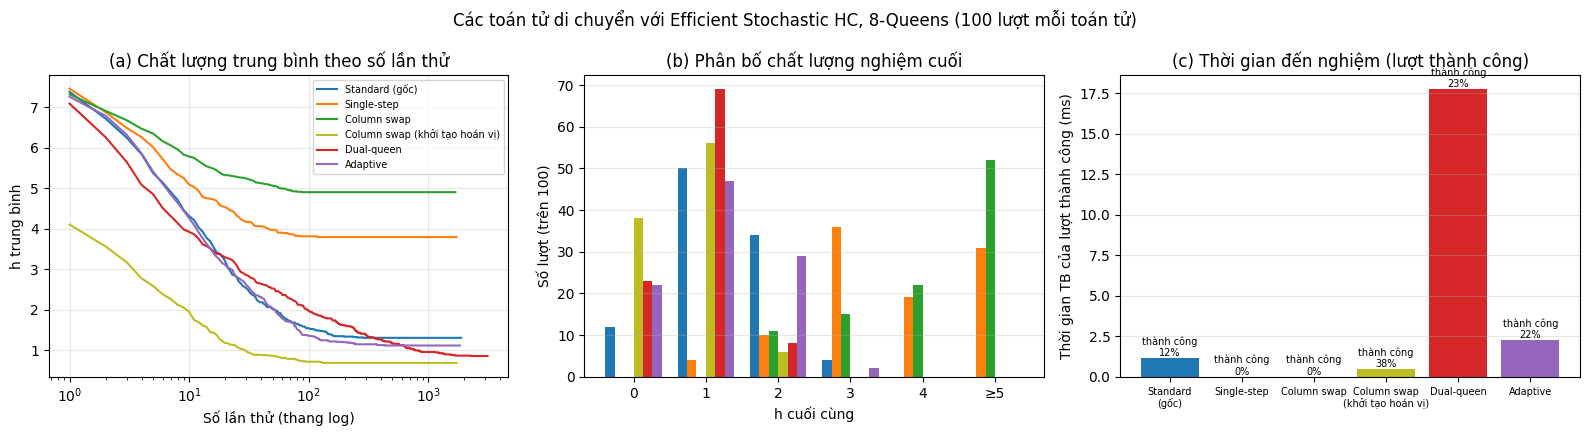

Đã lưu hình: figures/nq_11_toan_tu_di_chuyen_n12.png


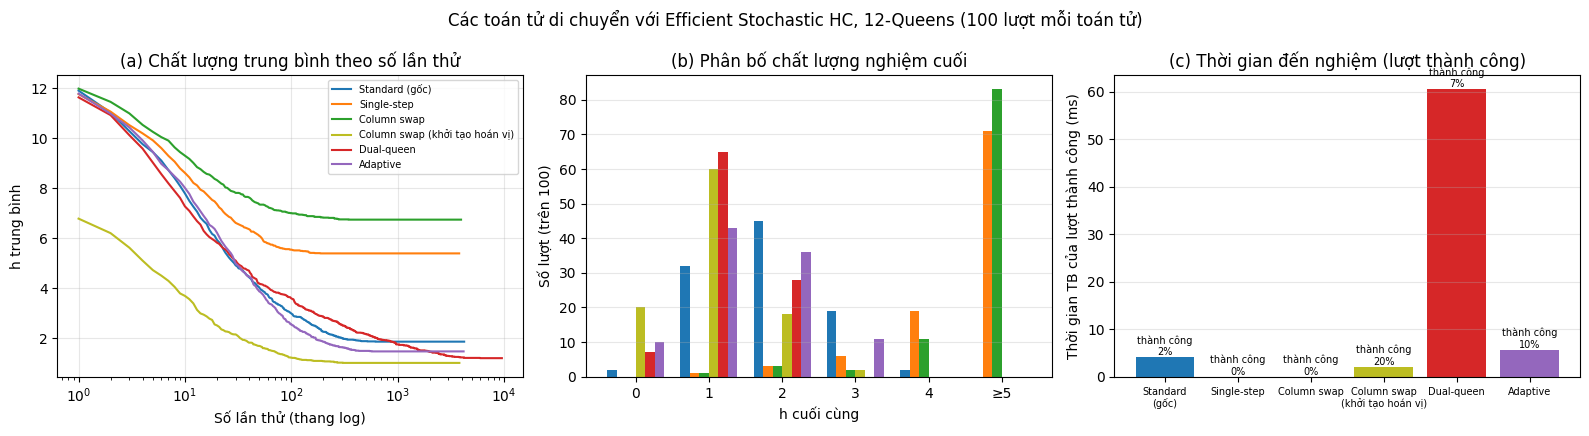

In [24]:
op_colors = dict(zip(OPERATORS, ['tab:blue', 'tab:orange', 'tab:green', 'tab:olive', 'tab:red', 'tab:purple']))

def plot_operators(n_, fname):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
    names = list(OPERATORS)
    # (a) chất lượng trung bình theo số lần thử
    for name in names:
        H = adv_results[(n_, name)][1]
        axes[0].plot(np.arange(1, H.shape[1]), H.mean(axis=0)[1:], label=name, color=op_colors[name])
    axes[0].set_xscale('log'); axes[0].set_xlabel('Số lần thử (thang log)'); axes[0].set_ylabel('h trung bình')
    axes[0].set_title('(a) Chất lượng trung bình theo số lần thử'); axes[0].legend(fontsize=7); axes[0].grid(True, alpha=0.3)
    # (b) phân bố h cuối
    cats = [0, 1, 2, 3, 4, 5]
    w = 0.13
    for j, name in enumerate(names):
        hv = adv_results[(n_, name)][0].h.values
        cnt = [int((hv == c).sum()) for c in cats[:-1]] + [int((hv >= 5).sum())]
        axes[1].bar(np.array(cats) + (j - 2.5) * w, cnt, w, label=name, color=op_colors[name])
    axes[1].set_xticks(cats); axes[1].set_xticklabels(['0', '1', '2', '3', '4', '≥5'])
    axes[1].set_xlabel('h cuối cùng'); axes[1].set_ylabel('Số lượt (trên 100)')
    axes[1].set_title('(b) Phân bố chất lượng nghiệm cuối'); axes[1].grid(True, axis='y', alpha=0.3)
    # (c) thời gian trung bình của các lượt thành công
    vals, labels = [], []
    for name in names:
        d = adv_results[(n_, name)][0]
        ok = d[d.h == 0]
        vals.append(1000 * ok.time.mean() if len(ok) else 0)
        labels.append(f'{len(ok)}%')
    bars = axes[2].bar(range(len(names)), vals, color=[op_colors[nm] for nm in names])
    for b_, lab in zip(bars, labels):
        axes[2].text(b_.get_x() + b_.get_width() / 2, b_.get_height(), 'thành công\n' + lab, ha='center', va='bottom', fontsize=7)
    axes[2].set_xticks(range(len(names))); axes[2].set_xticklabels([nm.replace(' (', '\n(') for nm in names], fontsize=7)
    axes[2].set_ylabel('Thời gian TB của lượt thành công (ms)'); axes[2].set_title('(c) Thời gian đến nghiệm (lượt thành công)')
    axes[2].grid(True, axis='y', alpha=0.3)
    fig.suptitle(f'Các toán tử di chuyển với Efficient Stochastic HC, {n_}-Queens (100 lượt mỗi toán tử)')
    plt.tight_layout()
    save_fig(fname)
    plt.show()

plot_operators(8, 'nq_10_toan_tu_di_chuyen_n8.png')
plot_operators(12, 'nq_11_toan_tu_di_chuyen_n12.png')

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

**Thảo luận** (Efficient Stochastic HC, 100 lượt mỗi toán tử, `patience = 25·n²`).

| Toán tử | Thành công n=8 | Thành công n=12 | Nhận xét |
|---|---|---|---|
| Standard (gốc) | 12 % | 2 % | mốc so sánh |
| Single-step | 0 % | 0 % | kẹt sớm, $h$ cuối TB 3,8 và 5,4 |
| Column swap (khởi tạo bất kỳ) | 0 % | 0 % | tệ nhất, $h$ cuối TB 4,9 và 6,8 |
| Column swap (khởi tạo hoán vị) | **38 %** | **20 %** | tốt nhất, nhanh nhất (0,5 ms, 30 lần thử) |
| Dual-queen | 23 % | 7 % | thành công cao nhưng chậm nhất (18 ms, 801 lần thử) |
| Adaptive | 22 % | 10 % | gần bằng dual-queen với chi phí thấp hơn nhiều (2,2 ms, 99 lần thử) |

* **Single-step** chỉ có khoảng $2n$ láng giềng và bước đi nhỏ, nên rất dễ rơi vào cực tiểu cục bộ và không thể "nhảy" qua rào cản; **không giải được** lượt nào.
* **Column swap** bảo toàn tập hàng đang dùng: từ bàn cờ ngẫu nhiên (có hai quân cùng hàng) xung đột hàng *không bao giờ* được loại bỏ, nên cũng 0 %. Khi **ràng buộc hàng/cột đã được mã hóa vào biểu diễn** (khởi tạo từ hoán vị, và swap giữ nguyên tính hoán vị) không gian tìm kiếm co từ $n^n$ còn $n!$ và chỉ còn xung đột đường chéo, thuật toán trở nên hiệu quả nhất (38 % ở $n=8$, 20 % ở $n=12$). Bài học: *chọn biểu diễn và toán tử phù hợp với cấu trúc ràng buộc* quan trọng hơn việc tinh chỉnh thuật toán.
* **Dual-queen** có láng giềng khổng lồ (với $n=8$: $\binom{8}{2}\cdot 7^2 = 1\,372$), nên mỗi nước cải thiện hiếm và cần nhiều lần thử (801 lần mỗi lượt thành công); bước nhảy lớn giúp thoát cực tiểu cục bộ (23 % so với 12 % của gốc) nhưng chậm.
* **Adaptive** (tập trung vào quân đang xung đột, xen kẽ dời hàng và hoán đổi) đạt thành công tương đương dual-queen ở $n=8$ chỉ với khoảng 1/8 số lần thử, vì không lãng phí thử nghiệm vào các quân đang không xung đột.
* **Hạn chế:** với 100 lượt, sai số chuẩn của tỷ lệ thành công khoảng 4 điểm phần trăm, nên chênh lệch giữa dual-queen và adaptive (23 % so với 22 % ở $n=8$; 7 % so với 10 % ở $n=12$) **không có ý nghĩa thống kê**; chỉ các khác biệt lớn (0 % so với 12 % so với 38 %) là đáng tin. Ngưỡng `patience` chung cũng ưu ái các toán tử có láng giềng nhỏ. Không toán tử nào đạt độ tin cậy cao như Simulated Annealing (99,8 % ở $n=8$), tức là việc đổi toán tử không thay thế được cơ chế thoát cực tiểu cục bộ.

## Bảng ghi kết quả thí nghiệm n-Queens (theo mẫu mục 4.2 của đề Lab)

"Thành công (%)" là tỷ lệ lượt chạy đạt $h = 0$. Hàng *Random Restart* là tỷ lệ trial đạt $h=0$ trong tối đa 100 lần chạy (Task 4), "Xung đột / COUNT" là số lần đánh giá $h$ trung bình của cả trial. Các đại lượng này **không đồng nhất** với `COUNT` của bài toán tô màu.

In [25]:
rows = []
def add(n_, name, runs, succ, conf_or_count, t_s):
    rows.append({'Bài toán': 'n-Queens', 'Kích thước': f'n = {n_}', 'Thuật toán': name, 'Số lượt': runs,
                 'Thành công (%)': round(succ, 1), 'Xung đột cuối TB': conf_or_count, 'Thời gian (s)': round(t_s, 6)})
for n_ in [4, 8]:
    for name in ALGOS6:
        d = runs6[(n_, name)]
        add(n_, name, N_RUNS, 100 * (d.h == 0).mean(), round(d.h.mean(), 3), d.time.mean())
    for name in HC_ALGOS:
        r = df_rr[(df_rr['n'] == n_) & (df_rr['Thuật toán'] == name)].iloc[0]
        rows.append({'Bài toán': 'n-Queens', 'Kích thước': f'n = {n_}', 'Thuật toán': f'Random Restart + {name}',
                     'Số lượt': TRIALS, 'Thành công (%)': round(r['Trial thành công (%)'], 1),
                     'Xung đột cuối TB': 0.0, 'Thời gian (s)': round(r['Thời gian TB (ms)'] / 1000, 6)})
df_table42_nq = pd.DataFrame(rows)
display(df_table42_nq)
save_table(df_table42_nq, 'nq_bang_4_2_tong_hop.csv')

,Bài toán,Kích thước,Thuật toán,Số lượt,Thành công (%),Xung đột cuối TB,Thời gian (s)
0,n-Queens,n = 4,Steepest asc. HC,500,41.8,0.654,0.000121
1,n-Queens,n = 4,Ineff. Stochastic HC,500,35.4,0.794,0.000138
2,n-Queens,n = 4,Efficient Stochastic HC,500,34.6,0.788,0.000590
3,n-Queens,n = 4,Simulated Annealing,500,100.0,0.000,0.000590
4,n-Queens,n = 4,Random Restart + Steepest-ascent HC,200,100.0,0.000,0.000490
5,n-Queens,n = 4,Random Restart + Inefficient stochastic HC,200,100.0,0.000,0.000458
6,n-Queens,n = 4,Random Restart + Efficient stochastic HC,200,100.0,0.000,0.001791
7,n-Queens,n = 8,Steepest asc. HC,500,14.6,1.256,0.001641
8,n-Queens,n = 8,Ineff. Stochastic HC,500,15.0,1.274,0.002342
9,n-Queens,n = 8,Efficient Stochastic HC,500,12.8,1.348,0.005500


Đã lưu bảng: results/nq_bang_4_2_tong_hop.csv


# Kết luận chung (phần n quân hậu)

* **Biểu diễn:** $h(\mathbf{q})$ = số cặp quân tấn công; $h=0$ đúng khi bàn cờ hợp lệ. Cách biểu diễn "mỗi cột một quân" đã loại sẵn một nhóm ràng buộc.
* **Hill Climbing** (steepest, inefficient, efficient) chỉ giải được khoảng 13–15 % bàn cờ 8×8 vì nhanh chóng kẹt, chủ yếu ở **plateau** (còn nước đi ngang) chứ ít khi ở cực tiểu cục bộ chặt; ba biến thể gần như tương đương về chất lượng và chỉ khác nhau về chi phí.
* **Random Restart** giúp cả ba biến thể thành công 100 % trong tối đa 100 lần chạy với trung bình khoảng $1/p \approx 7$ lần chạy ở $n=8$; steepest-ascent là rẻ nhất.
* **Simulated Annealing** đạt 99,8 % ở $n=8$ mà không cần khởi động lại; lịch logarit và nhiệt độ ở vùng trung gian cho kết quả tốt nhất, lịch quá nóng lãng phí vòng lặp còn lịch quá lạnh đóng băng sớm.
* **Khả năng mở rộng:** số mũ thực nghiệm khoảng 3,9–4,0 (steepest/inefficient), 3,3 (efficient) và 2,6 khi tính $\Delta h$ trong $O(1)$: cài đặt ảnh hưởng mạnh đến độ phức tạp quan sát được. Ở $n$ lớn chỉ SA giải ổn định.
* **Toán tử di chuyển:** swap trên hoán vị là tốt nhất; single-step và swap trên bàn cờ không phải hoán vị không giải được; dual-queen và adaptive cải thiện vừa phải so với toán tử gốc.
* **Hạn chế đánh giá:** kết quả phụ thuộc vào Python, hạt giống, số lượt chạy (100–500) và các tham số (`patience`, `max_iters`, lịch làm nguội); chênh lệch nhỏ hơn vài điểm phần trăm không đáng tin. Vì vậy cần cố định điều kiện thí nghiệm, dùng cùng bộ bàn cờ khởi tạo và lặp nhiều lần khi đánh giá thuật toán ngẫu nhiên.

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment.

### Implement a Genetic Algorithm for the n-Queens problem